# Redes neurais com PyTorch

Redes de aprendizado profundo (Deep Learning) tendem a ser massivas, com dezenas ou centenas de camadas, que é de onde vem o termo "profundo" (deep). Você pode construir uma dessas redes profundas usando apenas matrizes de pesos como fizemos no notebook anterior, mas no geral isso é muito trabalhoso e difícil de implementar. O PyTorch possui um módulo excelente chamado `nn` que fornece uma maneira eficiente de construir grandes redes neurais.

In [25]:
# Import necessary packages

%matplotlib inline
%config InlineBackend.figure_format = 'retina'

import numpy as np
import torch

import helper

import matplotlib.pyplot as plt

Agora nós vamos construir uma rede maior que consegue resolver um problema que antes era considerado difícil: identificar texto em uma imagem. Aqui usaremos o conjunto de dados MNIST, que consiste em imagens em tons de cinza de dígitos manuscritos. Cada imagem tem 28x28 pixels, e você pode ver uma amostra abaixo:

<img src='assets/mnist.png'>

Nosso objetivo é construir uma rede neural que consiga receber uma dessas imagens e prever qual é o dígito na imagem.

Primeiro, precisamos obter o nosso conjunto de dados. Isso é fornecido através do pacote `torchvision`. O código abaixo irá baixar o dataset MNIST e depois criar os conjuntos de dados de treino e teste para nós. Não se preocupe muito com os detalhes aqui por enquanto, você aprenderá mais sobre isso mais tarde.

In [26]:
# The MNIST datasets are hosted on yann.lecun.com that has moved under CloudFlare protection
# Run this script to enable the datasets download
# Reference: https://github.com/pytorch/vision/issues/1938

from six.moves import urllib
opener = urllib.request.build_opener()
opener.addheaders = [('User-agent', 'Mozilla/5.0')]
urllib.request.install_opener(opener)

In [27]:
### Run this cell

from torchvision import datasets, transforms

# Define a transform to normalize the data
transform = transforms.Compose([transforms.ToTensor(),
                              transforms.Normalize((0.5,), (0.5,)),
                              ])

# Download and load the training data
trainset = datasets.MNIST('~/.pytorch/MNIST_data/', download=True, train=True, transform=transform)
trainloader = torch.utils.data.DataLoader(trainset, batch_size=64, shuffle=True)

Temos os dados de treinamento carregados em `trainloader` e transformamos isso em um iterador com `iter(trainloader)`. Mais tarde, usaremos isso para percorrer o conjunto de dados durante o treinamento, desta forma:

```python
for image, label in trainloader:
    ## faz coisas com as imagens e rótulos
```

Você deve ter notado que criei o `trainloader` com um tamanho de lote (batch size) de 64 e `shuffle=True`. O tamanho do lote é o número de imagens que obtemos em uma única iteração do carregador de dados e passamos pela nossa rede (geralmente chamado de *lote* ou *batch*). E `shuffle=True` diz para embaralhar o conjunto de dados toda vez que começarmos a percorrer o carregador de dados novamente. Mas aqui estou apenas pegando o primeiro lote para podermos inspecionar os dados. Podemos ver abaixo que `images` é apenas um tensor com tamanho `(64, 1, 28, 28)`. Ou seja, 64 imagens por lote, 1 canal de cor (cinza) e imagens de tamanho 28x28.

In [28]:
dataiter = iter(trainloader)
images, labels = next(dataiter)
print(type(images))
print(images.shape)
print(labels.shape)

<class 'torch.Tensor'>
torch.Size([64, 1, 28, 28])
torch.Size([64])


Esta é a aparência de uma das imagens.

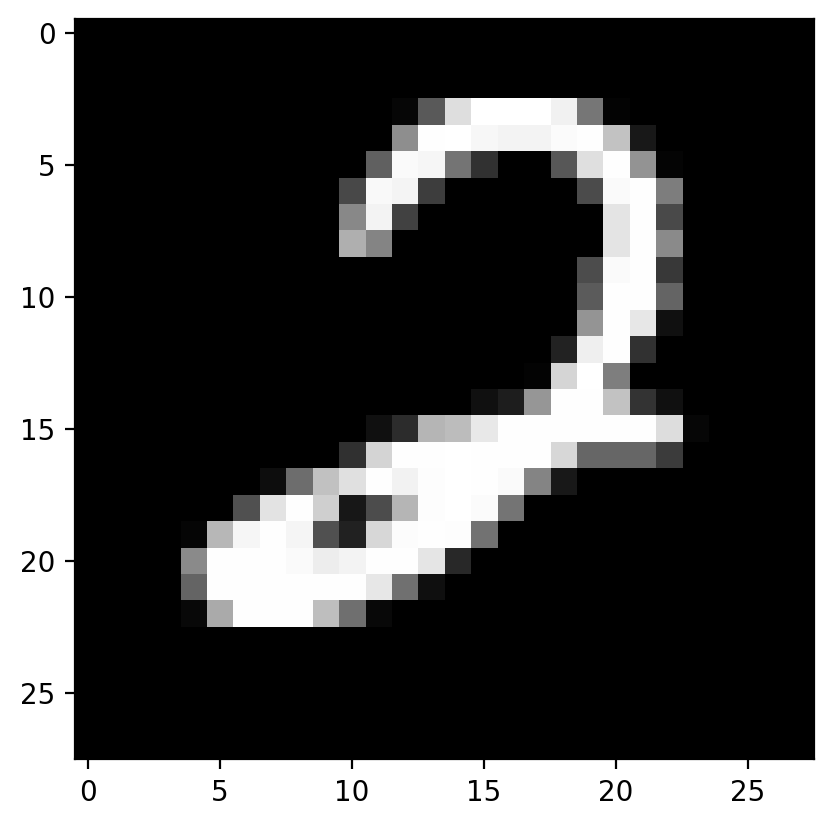

In [29]:
plt.imshow(images[1].numpy().squeeze(), cmap='Greys_r');

Primeiro, vamos tentar construir uma rede simples para este conjunto de dados usando matrizes de pesos e multiplicações de matrizes. Depois, veremos como fazer isso usando o módulo `nn` do PyTorch, que fornece um método muito mais conveniente e poderoso para definir arquiteturas de rede.

As redes que você viu até agora são chamadas de redes *totalmente conectadas* (fully-connected) ou *densas* (dense). Cada unidade em uma camada está conectada a cada unidade na camada seguinte. Em redes totalmente conectadas, a entrada para cada camada deve ser um vetor unidimensional (que pode ser empilhado em um tensor 2D como um lote de múltiplos exemplos). No entanto, nossas imagens são tensores 2D de 28x28, então precisamos convertê-los em vetores 1D. Pensando nos tamanhos, precisamos converter o lote de imagens com formato `(64, 1, 28, 28)` para um formato de `(64, 784)`, onde 784 é 28 vezes 28. Isso é normalmente chamado de *achatamento* (flattening), pois "achatamos" as imagens 2D em vetores 1D.

Anteriormente, você construiu uma rede com uma única unidade de saída. Aqui precisamos de 10 unidades de saída, uma para cada dígito. Queremos que nossa rede preveja o dígito mostrado em uma imagem, então o que faremos é calcular probabilidades de que a imagem seja de qualquer um dos dígitos ou classes. Isso resulta em uma distribuição de probabilidade discreta sobre as classes (dígitos) que nos diz a classe mais provável para a imagem. Isso significa que precisamos de 10 unidades de saída para as 10 classes (dígitos). Veremos como converter a saída da rede em uma distribuição de probabilidade a seguir.

> **Exercício:** Achate o lote de imagens `images`. Em seguida, construa uma rede de múltiplas camadas com 784 unidades de entrada, 256 unidades ocultas e 10 unidades de saída usando tensores aleatórios para os pesos e bias. Por enquanto, use uma ativação sigmoide para a camada oculta. Deixe a camada de saída sem ativação, adicionaremos uma que nos dá uma distribuição de probabilidade a seguir.

In [30]:
## Sua solução

# 1. Achatar as imagens para o tamanho (64, 784)
inputs = images.view(images.shape[0], -1)

# 2. Definir pesos e bias usando tensores aleatórios
# Entrada para camada oculta (784 -> 256)
w1 = torch.randn(784, 256)
b1 = torch.randn(256)

# Camada oculta para saída (256 -> 10)
w2 = torch.randn(256, 10)
b2 = torch.randn(10)

# Função de ativação sigmoide
def sigmoid_activation(x):
    return 1 / (1 + torch.exp(-x))

# 3. Passagem direta (Forward pass)
h = sigmoid_activation(torch.mm(inputs, w1) + b1)
out = torch.mm(h, w2) + b2 # saída da rede, deve ter tamanho (64, 10)

# Verificar o formato da saída
print(out.shape)

torch.Size([64, 10])


Now we have 10 outputs for our network. We want to pass in an image to our network and get out a probability distribution over the classes that tells us the likely class(es) the image belongs to. Something that looks like this:
<img src='assets/image_distribution.png' width=500px>

Here we see that the probability for each class is roughly the same. This is representing an untrained network, it hasn't seen any data yet so it just returns a uniform distribution with equal probabilities for each class.

To calculate this probability distribution, we often use the [**softmax** function](https://en.wikipedia.org/wiki/Softmax_function). Mathematically this looks like

$$
\Large \sigma(x_i) = \cfrac{e^{x_i}}{\sum_k^K{e^{x_k}}}
$$

What this does is squish each input $x_i$ between 0 and 1 and normalizes the values to give you a proper probability distribution where the probabilites sum up to one.

> **Exercise:** Implement a function `softmax` that performs the softmax calculation and returns probability distributions for each example in the batch. Note that you'll need to pay attention to the shapes when doing this. If you have a tensor `a` with shape `(64, 10)` and a tensor `b` with shape `(64,)`, doing `a/b` will give you an error because PyTorch will try to do the division across the columns (called broadcasting) but you'll get a size mismatch. The way to think about this is for each of the 64 examples, you only want to divide by one value, the sum in the denominator. So you need `b` to have a shape of `(64, 1)`. This way PyTorch will divide the 10 values in each row of `a` by the one value in each row of `b`. Pay attention to how you take the sum as well. You'll need to define the `dim` keyword in `torch.sum`. Setting `dim=0` takes the sum across the rows while `dim=1` takes the sum across the columns.

In [31]:
def softmax(x):
    ## TODO: Implement the softmax function here
    # Calcula e^x para cada elemento
    exp_x = torch.exp(x)
    # Soma os exponenciais de cada linha (dim=1) mantendo a dimensão para broadcasting (64, 1)
    sum_exp_x = torch.sum(exp_x, dim=1, keepdim=True)
    # Retorna a divisão elemento a elemento
    return exp_x / sum_exp_x

# Here, out should be the output of the network in the previous excercise with shape (64,10)
probabilities = softmax(out)

# Does it have the right shape? Should be (64, 10)
print(probabilities.shape)
# Does it sum to 1?
print(probabilities.sum(dim=1))

torch.Size([64, 10])
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000, 1.0000,
        1.0000])


## Building networks with PyTorch

PyTorch provides a module `nn` that makes building networks much simpler. Here I'll show you how to build the same one as above with 784 inputs, 256 hidden units, 10 output units and a softmax output.

In [32]:
from torch import nn

In [33]:
class Network(nn.Module):
    def __init__(self):
        super().__init__()

        # Inputs to hidden layer linear transformation
        self.hidden = nn.Linear(784, 256)
        # Output layer, 10 units - one for each digit
        self.output = nn.Linear(256, 10)

        # Define sigmoid activation and softmax output
        self.sigmoid = nn.Sigmoid()
        self.softmax = nn.Softmax(dim=1)

    def forward(self, x):
        # Pass the input tensor through each of our operations
        x = self.hidden(x)
        x = self.sigmoid(x)
        x = self.output(x)
        x = self.softmax(x)

        return x

Let's go through this bit by bit.

```python
class Network(nn.Module):
```

Here we're inheriting from `nn.Module`. Combined with `super().__init__()` this creates a class that tracks the architecture and provides a lot of useful methods and attributes. It is mandatory to inherit from `nn.Module` when you're creating a class for your network. The name of the class itself can be anything.

```python
self.hidden = nn.Linear(784, 256)
```

This line creates a module for a linear transformation, $x\mathbf{W} + b$, with 784 inputs and 256 outputs and assigns it to `self.hidden`. The module automatically creates the weight and bias tensors which we'll use in the `forward` method. You can access the weight and bias tensors once the network (`net`) is created with `net.hidden.weight` and `net.hidden.bias`.

```python
self.output = nn.Linear(256, 10)
```

Similarly, this creates another linear transformation with 256 inputs and 10 outputs.

```python
self.sigmoid = nn.Sigmoid()
self.softmax = nn.Softmax(dim=1)
```

Here I defined operations for the sigmoid activation and softmax output. Setting `dim=1` in `nn.Softmax(dim=1)` calculates softmax across the columns.

```python
def forward(self, x):
```

PyTorch networks created with `nn.Module` must have a `forward` method defined. It takes in a tensor `x` and passes it through the operations you defined in the `__init__` method.

```python
x = self.hidden(x)
x = self.sigmoid(x)
x = self.output(x)
x = self.softmax(x)
```

Here the input tensor `x` is passed through each operation and reassigned to `x`. We can see that the input tensor goes through the hidden layer, then a sigmoid function, then the output layer, and finally the softmax function. It doesn't matter what you name the variables here, as long as the inputs and outputs of the operations match the network architecture you want to build. The order in which you define things in the `__init__` method doesn't matter, but you'll need to sequence the operations correctly in the `forward` method.

Now we can create a `Network` object.

In [34]:
# Create the network and look at it's text representation
model = Network()
model

Network(
  (hidden): Linear(in_features=784, out_features=256, bias=True)
  (output): Linear(in_features=256, out_features=10, bias=True)
  (sigmoid): Sigmoid()
  (softmax): Softmax(dim=1)
)

You can define the network somewhat more concisely and clearly using the `torch.nn.functional` module. This is the most common way you'll see networks defined as many operations are simple element-wise functions. We normally import this module as `F`, `import torch.nn.functional as F`.

In [35]:
import torch.nn.functional as F

class Network(nn.Module):
    def __init__(self):
        super().__init__()
        # Inputs to hidden layer linear transformation
        self.hidden = nn.Linear(784, 256)
        # Output layer, 10 units - one for each digit
        self.output = nn.Linear(256, 10)

    def forward(self, x):
        # Hidden layer with sigmoid activation
        x = F.sigmoid(self.hidden(x))
        # Output layer with softmax activation
        x = F.softmax(self.output(x), dim=1)

        return x

### Activation functions

So far we've only been looking at the sigmoid activation function, but in general any function can be used as an activation function. The only requirement is that for a network to approximate a non-linear function, the activation functions must be non-linear. Here are a few more examples of common activation functions: Tanh (hyperbolic tangent), and ReLU (rectified linear unit).

<img src="assets/activation.png" width=700px>

In practice, the ReLU function is used almost exclusively as the activation function for hidden layers.

### Your Turn to Build a Network

<img src="assets/mlp_mnist.png" width=600px>

> **Exercise:** Create a network with 784 input units, a hidden layer with 128 units and a ReLU activation, then a hidden layer with 64 units and a ReLU activation, and finally an output layer with a softmax activation as shown above. You can use a ReLU activation with the `nn.ReLU` module or `F.relu` function.

It's good practice to name your layers by their type of network, for instance 'fc' to represent a fully-connected layer. As you code your solution, use `fc1`, `fc2`, and `fc3` as your layer names.

In [36]:
class Network(nn.Module):
    def __init__(self):
        super().__init__()
        # Definindo as camadas lineares conforme as instruções
        self.fc1 = nn.Linear(784, 128)
        self.fc2 = nn.Linear(128, 64)
        self.fc3 = nn.Linear(64, 10)

    def forward(self, x):
        # Passagem direta usando ativação ReLU e Softmax na saída
        x = F.relu(self.fc1(x))
        x = F.relu(self.fc2(x))
        x = F.softmax(self.fc3(x), dim=1)

        return x

# Criando uma instância do modelo para teste
model = Network()
print(model)

Network(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (fc3): Linear(in_features=64, out_features=10, bias=True)
)


### Initializing weights and biases

The weights and such are automatically initialized for you, but it's possible to customize how they are initialized. The weights and biases are tensors attached to the layer you defined, you can get them with `model.fc1.weight` for instance.

In [37]:
print(model.fc1.weight)
print(model.fc1.bias)

Parameter containing:
tensor([[-0.0140,  0.0057,  0.0125,  ..., -0.0165, -0.0167, -0.0252],
        [-0.0236,  0.0314, -0.0247,  ..., -0.0309, -0.0160,  0.0233],
        [-0.0190, -0.0081, -0.0173,  ..., -0.0337,  0.0099, -0.0281],
        ...,
        [-0.0073, -0.0029, -0.0070,  ..., -0.0216,  0.0141, -0.0031],
        [ 0.0131, -0.0102, -0.0050,  ..., -0.0281, -0.0244, -0.0315],
        [ 0.0084,  0.0207,  0.0202,  ...,  0.0286,  0.0226,  0.0353]],
       requires_grad=True)
Parameter containing:
tensor([-1.1813e-02,  2.1476e-02,  5.7421e-03,  3.2456e-02,  1.8712e-02,
        -9.2297e-04,  1.2688e-02, -2.1643e-02, -1.0573e-02, -1.6989e-02,
         2.1040e-02,  9.7632e-03, -2.3228e-02,  2.2365e-02,  4.2889e-03,
        -3.5461e-03, -3.4648e-02,  2.5289e-02,  7.9396e-03,  2.3489e-02,
         3.5151e-02,  5.9100e-03,  3.5217e-02,  2.9144e-02, -3.4446e-02,
         3.5288e-02,  2.0553e-02,  1.9371e-03,  4.2341e-03, -2.9800e-02,
         3.6518e-03, -2.4033e-02, -2.2448e-02,  2.5851e-0

For custom initialization, we want to modify these tensors in place. These are actually autograd *Variables*, so we need to get back the actual tensors with `model.fc1.weight.data`. Once we have the tensors, we can fill them with zeros (for biases) or random normal values.

In [38]:
# Set biases to all zeros
model.fc1.bias.data.fill_(0)

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0.])

In [39]:
# sample from random normal with standard dev = 0.01
model.fc1.weight.data.normal_(std=0.01)

tensor([[ 0.0080, -0.0201, -0.0229,  ..., -0.0008, -0.0050, -0.0062],
        [ 0.0075, -0.0098, -0.0022,  ...,  0.0055, -0.0075, -0.0006],
        [-0.0008,  0.0091,  0.0017,  ...,  0.0048,  0.0128,  0.0052],
        ...,
        [ 0.0042,  0.0011, -0.0018,  ..., -0.0004, -0.0148, -0.0054],
        [ 0.0010,  0.0065, -0.0149,  ...,  0.0007,  0.0043,  0.0104],
        [ 0.0027, -0.0234, -0.0022,  ...,  0.0099, -0.0138,  0.0152]])

### Forward pass

Now that we have a network, let's see what happens when we pass in an image.

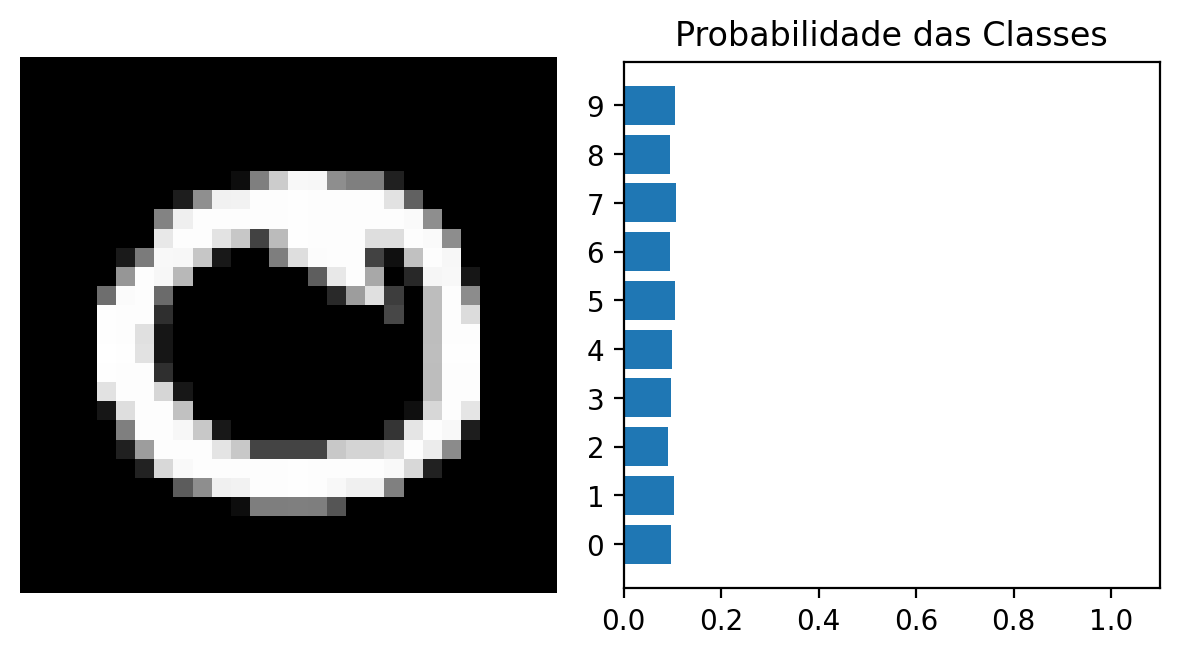

In [41]:
# Grab some data
dataiter = iter(trainloader)
images, labels = next(dataiter)

# Resize images into a 1D vector
images.resize_(64, 1, 784)

# Forward pass through the network
img_idx = 0
ps = model.forward(images[img_idx,:])

# Desconectar o gradiente para plotar com numpy
ps = ps.data.numpy().squeeze()

img = images[img_idx]

# Criando uma função de visualização alternativa local para evitar o erro do helper
fig, (ax1, ax2) = plt.subplots(figsize=(6,9), ncols=2)
ax1.imshow(img.view(1, 28, 28).numpy().squeeze(), cmap='Greys_r')
ax1.axis('off')
ax2.barh(np.arange(10), ps)
ax2.set_aspect(0.1)
ax2.set_yticks(np.arange(10))
ax2.set_yticklabels(np.arange(10))
ax2.set_title('Probabilidade das Classes')
ax2.set_xlim(0, 1.1)
plt.tight_layout()

As you can see above, our network has basically no idea what this digit is. It's because we haven't trained it yet, all the weights are random!

### Using `nn.Sequential`

PyTorch provides a convenient way to build networks like this where a tensor is passed sequentially through operations, `nn.Sequential` ([documentation](https://pytorch.org/docs/master/nn.html#torch.nn.Sequential)). Using this to build the equivalent network:

Sequential(
  (0): Linear(in_features=784, out_features=128, bias=True)
  (1): ReLU()
  (2): Linear(in_features=128, out_features=64, bias=True)
  (3): ReLU()
  (4): Linear(in_features=64, out_features=10, bias=True)
  (5): Softmax(dim=1)
)


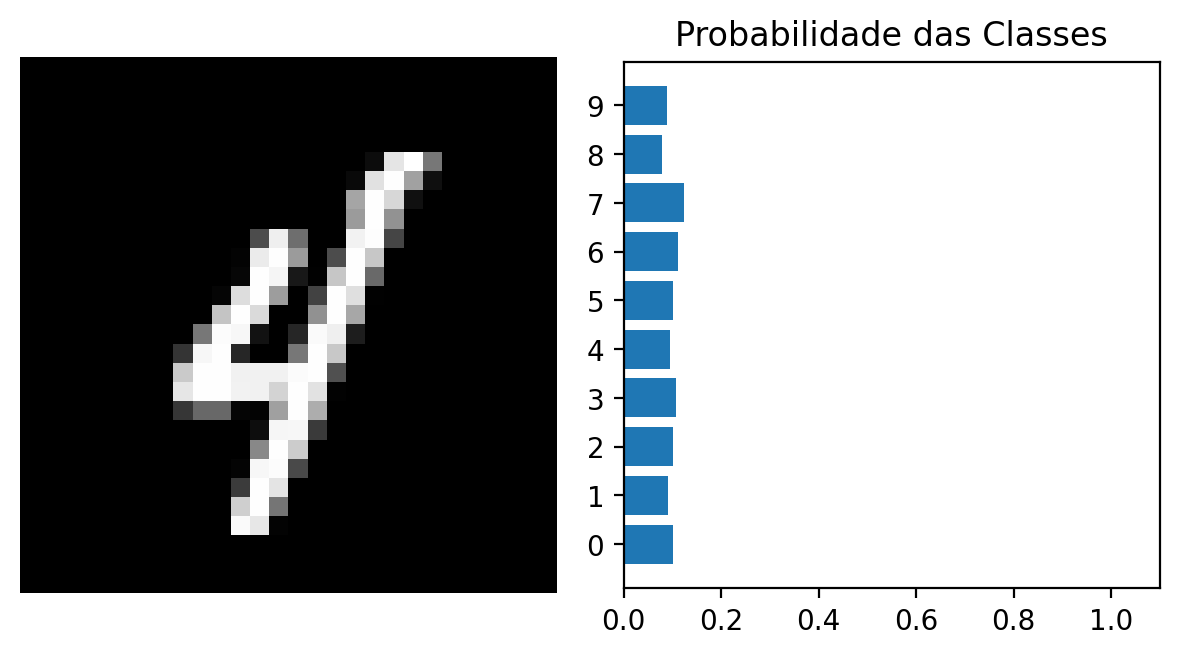

In [43]:
# Hyperparameters for our network
input_size = 784
hidden_sizes = [128, 64]
output_size = 10

# Build a feed-forward network
model = nn.Sequential(nn.Linear(input_size, hidden_sizes[0]),
                      nn.ReLU(),
                      nn.Linear(hidden_sizes[0], hidden_sizes[1]),
                      nn.ReLU(),
                      nn.Linear(hidden_sizes[1], output_size),
                      nn.Softmax(dim=1))
print(model)

# Forward pass through the network and display output
images, labels = next(iter(trainloader))
images.resize_(images.shape[0], 1, 784)

# Desconectar o gradiente para plotagem do PyTorch para o NumPy
ps = model.forward(images[0,:]).data.numpy().squeeze()
img = images[0]

# Visualização alternativa local usando matplotlib para evitar o erro do helper
fig, (ax1, ax2) = plt.subplots(figsize=(6,9), ncols=2)
ax1.imshow(img.view(1, 28, 28).numpy().squeeze(), cmap='Greys_r')
ax1.axis('off')
ax2.barh(np.arange(10), ps)
ax2.set_aspect(0.1)
ax2.set_yticks(np.arange(10))
ax2.set_yticklabels(np.arange(10))
ax2.set_title('Probabilidade das Classes')
ax2.set_xlim(0, 1.1)
plt.tight_layout()

Here our model is the same as before: 784 input units, a hidden layer with 128 units, ReLU activation, 64 unit hidden layer, another ReLU, then the output layer with 10 units, and the softmax output.

The operations are available by passing in the appropriate index. For example, if you want to get first Linear operation and look at the weights, you'd use `model[0]`.

In [44]:
print(model[0])
model[0].weight

Linear(in_features=784, out_features=128, bias=True)


Parameter containing:
tensor([[-0.0040, -0.0065, -0.0107,  ..., -0.0049,  0.0054, -0.0318],
        [ 0.0154,  0.0161,  0.0049,  ..., -0.0056, -0.0015, -0.0034],
        [ 0.0179,  0.0246, -0.0213,  ..., -0.0245, -0.0078,  0.0172],
        ...,
        [ 0.0160,  0.0251, -0.0209,  ..., -0.0182,  0.0143,  0.0059],
        [ 0.0155,  0.0087, -0.0177,  ...,  0.0064,  0.0095,  0.0124],
        [ 0.0073,  0.0037, -0.0192,  ...,  0.0107, -0.0011,  0.0115]],
       requires_grad=True)

You can also pass in an `OrderedDict` to name the individual layers and operations, instead of using incremental integers. Note that dictionary keys must be unique, so _each operation must have a different name_.

In [45]:
from collections import OrderedDict
model = nn.Sequential(OrderedDict([
                      ('fc1', nn.Linear(input_size, hidden_sizes[0])),
                      ('relu1', nn.ReLU()),
                      ('fc2', nn.Linear(hidden_sizes[0], hidden_sizes[1])),
                      ('relu2', nn.ReLU()),
                      ('output', nn.Linear(hidden_sizes[1], output_size)),
                      ('softmax', nn.Softmax(dim=1))]))
model

Sequential(
  (fc1): Linear(in_features=784, out_features=128, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=128, out_features=64, bias=True)
  (relu2): ReLU()
  (output): Linear(in_features=64, out_features=10, bias=True)
  (softmax): Softmax(dim=1)
)

Now you can access layers either by integer or the name

In [46]:
print(model[0])
print(model.fc1)

Linear(in_features=784, out_features=128, bias=True)
Linear(in_features=784, out_features=128, bias=True)


In the next notebook, we'll see how we can train a neural network to accuractly predict the numbers appearing in the MNIST images.